# 06. Tempo até o tratamento

Quanto tempo uma mulher espera entre procurar o hospital, receber o diagnóstico e começar a se tratar? A Lei 12.732, de 2012, garante que o primeiro tratamento no SUS comece em até 60 dias após o diagnóstico. Este caderno mede o quanto esse prazo é cumprido e detalha a espera em faixas: até 30 dias, até 60, até 90, até 6 meses, até 1 ano, até 2 anos e mais de 2 anos.

Duas fontes são usadas, e elas medem coisas um pouco diferentes. O Painel de Oncologia cobre o SUS inteiro e foi criado justamente para monitorar a lei dos 60 dias; ele mede o tempo entre o diagnóstico e o primeiro tratamento registrado no SUS. O RHC cobre os hospitais com registro de câncer e tem três datas: a primeira consulta no hospital, o diagnóstico e o início do tratamento. Com ele, dá para ver também quanto tempo se leva para fechar o diagnóstico depois de chegar ao hospital.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g, harmonizacao as h
from mama.config import FONTE_PAINEL, FONTE_RHC
from mama.analises import base, tempos

pd.set_option("display.max_columns", 20)
painel = tempos.painel_tratadas(base.painel())
rhc = base.rhc()
for df in (painel, rhc):
    df["grupo_idade"] = h.grupo_50(df.idade)
print(f"Painel: {len(painel):,} mulheres com tratamento registrado (2013 a 2024)")
print(f"RHC: {len(rhc):,} mulheres (2013 a 2022)")

# Faixas de tempo em tons de azul, do mais curto (claro) ao mais longo (escuro)
CORES_TEMPO = dict(zip(c.INTERVALOS_ROTULOS, ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]))

Painel: 494,562 mulheres com tratamento registrado (2013 a 2024)
RHC: 351,299 mulheres (2013 a 2022)


## Do diagnóstico ao tratamento no SUS

O gráfico divide as mulheres de cada região pelo tempo que esperaram entre o diagnóstico e o primeiro tratamento. As duas primeiras faixas, mais claras, são as que cumprem a lei.

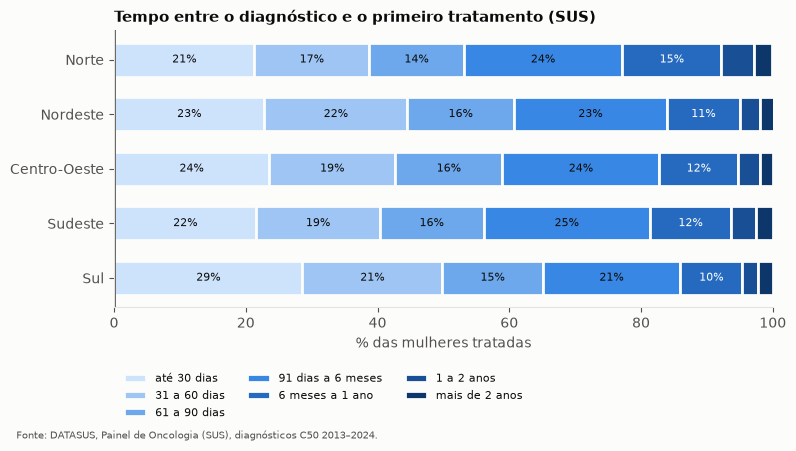

intervalo,até 30 dias,31 a 60 dias,61 a 90 dias,91 dias a 6 meses,6 meses a 1 ano,1 a 2 anos,mais de 2 anos
regiao_res,,,,,,,
Norte,21.3,17.4,14.4,24.0,15.1,4.9,2.8
Nordeste,22.8,21.7,16.2,23.2,11.1,3.0,2.2
Centro-Oeste,23.5,19.2,16.2,23.9,11.9,3.4,1.9
Sudeste,21.6,18.7,15.8,25.2,12.4,3.7,2.6
Sul,28.6,21.2,15.3,20.8,9.5,2.4,2.2


In [2]:
dist = tempos.distribuicao_intervalos(painel, "dias_diagnostico_tratamento", "regiao_res")
base.salvar_tabela(dist, "06_painel_faixas_tempo_regiao", index=True)
fig, ax = g.empilhadas_100(dist, "Tempo entre o diagnóstico e o primeiro tratamento (SUS)",
                           "% das mulheres tratadas", cores=CORES_TEMPO, minimo_rotulo=5, figsize=(8.5, 3.6))
ax.axvline(0, color=g.TEXTO_2)
g.salvar(fig, "06_faixas_tempo_regiao", FONTE_PAINEL)
plt.show()
dist

Somando as duas primeiras faixas, só entre 39% (Norte) e 50% (Sul) das mulheres começam o tratamento dentro dos 60 dias previstos em lei. Isso significa que, em todas as regiões, metade ou mais das pacientes espera mais do que o prazo legal.

As faixas mais longas mostram o tamanho do problema. Uma em cada quatro mulheres espera de 3 a 6 meses. No Norte, 15% esperam de 6 meses a 1 ano e quase 8% esperam mais de 1 ano. Para um câncer que pode progredir de um estádio a outro em alguns meses, esse atraso pode mudar o prognóstico.

## Resumo por região

A tabela traz, para cada região, a mediana de dias (metade das mulheres espera menos que isso, metade espera mais), o intervalo em que estão as 50% centrais (p25 a p75) e o percentual que passa de 60 dias, de 6 meses e de 1 ano.

In [3]:
resumo = tempos.resumo(painel, "dias_diagnostico_tratamento", ["regiao_res"])
base.salvar_tabela(resumo, "06_painel_resumo_tempo_regiao")
resumo

,regiao_res,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Centro-Oeste,31480,73.0,33.0,139.0,57.3,17.2,5.3
1,Nordeste,114986,70.0,34.0,133.0,55.6,16.2,5.2
2,Norte,20328,83.0,37.0,168.0,61.2,22.9,7.8
3,Sudeste,226009,78.0,36.0,147.0,59.7,18.7,6.3
4,Sul,101759,61.0,26.0,119.0,50.2,14.1,4.6


A mediana vai de 61 dias no Sul a 83 dias no Norte. Ou seja, mesmo no Sul, a mulher típica já passa do prazo legal.

## A espera dentro do hospital: consulta, diagnóstico e tratamento

O RHC permite dividir a espera em duas etapas. A primeira vai da primeira consulta no hospital até a confirmação do diagnóstico. A segunda vai do diagnóstico até o início do tratamento. Muitas mulheres já chegam ao hospital com o diagnóstico feito em outro serviço, e nesse caso a primeira etapa é zero ou negativa (e é descartada do cálculo).

In [4]:
etapas = pd.concat({
    "Consulta até diagnóstico": tempos.resumo(rhc, "dias_consulta_diagnostico", ["regiao_res"]).set_index("regiao_res"),
    "Diagnóstico até tratamento": tempos.resumo(rhc, "dias_diagnostico_tratamento", ["regiao_res"]).set_index("regiao_res"),
    "Consulta até tratamento": tempos.resumo(rhc, "dias_consulta_tratamento", ["regiao_res"]).set_index("regiao_res"),
}, names=["etapa", "regiao"])[["n", "mediana", "pct_mais_60_dias", "pct_mais_6_meses", "pct_mais_1_ano"]]
base.salvar_tabela(etapas, "06_rhc_etapas_tempo", index=True)
etapas

n  mediana  pct_mais_60_dias  \
etapa                      regiao                                            
Consulta até diagnóstico   Centro-Oeste    5675     22.0              22.7   
                           Nordeste       34249     21.0              17.9   
                           Norte           3444     26.0              26.2   
                           Sudeste        61222     14.0              14.0   
                           Sul            29063     18.0              16.6   
Diagnóstico até tratamento Centro-Oeste   14134     82.0              63.1   
                           Nordeste       81824     64.0              52.5   
                           Norte          15206     88.0              64.8   
                           Sudeste       151597     74.0              59.7   
                           Sul            62623     62.0              51.1   
Consulta até tratamento    Centro-Oeste   14665     45.0              40.1   
                           Nordeste       85404     40.0              34.8   
                           Norte          15588     45.0              41.6   
                           Sudeste       156068     48.0              39.7   
                           Sul            66056     40.0              35.0   

                                         pct_mais_6_meses  pct_mais_1_ano  
etapa                      regiao                                          
Consulta até diagnóstico   Centro-Oeste               5.2             1.4  
                           Nordeste                   3.2             0.8  
                           Norte                      6.9             1.4  
                           Sudeste                    2.3             0.5  
                           Sul                        3.1             0.7  
Diagnóstico até tratamento Centro-Oeste              17.7             5.4  
                           Nordeste                  15.4             4.9  
                           Norte                     23.1             7.4  
                           Sudeste                   12.1             2.4  
                           Sul                       14.6             5.3  
Consulta até tratamento    Centro-Oeste               8.7             1.9  
                           Nordeste                   6.0             1.2  
                           Norte                     11.7             2.4  
                           Sudeste                    5.7             1.0  
                           Sul                        6.9             2.1

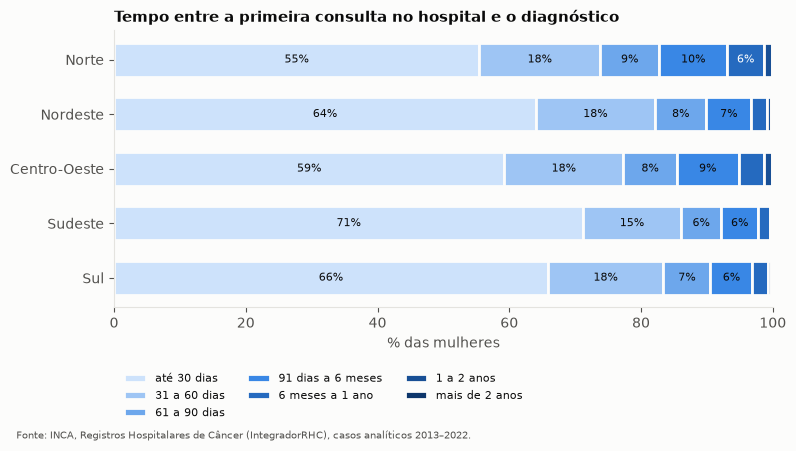

In [5]:
dist_cd = tempos.distribuicao_intervalos(rhc, "dias_consulta_diagnostico", "regiao_res")
fig, ax = g.empilhadas_100(dist_cd, "Tempo entre a primeira consulta no hospital e o diagnóstico",
                           "% das mulheres", cores=CORES_TEMPO, minimo_rotulo=5, figsize=(8.5, 3.6))
g.salvar(fig, "06_consulta_diagnostico_regiao", FONTE_RHC)
plt.show()

Dentro do hospital, a confirmação do diagnóstico costuma ser rápida: em todas as regiões, mais da metade das mulheres tem o diagnóstico em até 30 dias após a primeira consulta. Mas o Norte se destaca de novo, com 17% esperando mais de 3 meses só por essa etapa, contra 8% no Sudeste.

Somando as etapas, a mediana entre a primeira consulta e o início do tratamento fica entre 40 e 48 dias no RHC. Ela é menor do que a do Painel porque o RHC conta a partir da chegada ao hospital, e boa parte da espera acontece antes disso, na atenção primária, na fila de exames e na regulação, uma etapa que nenhuma base pública registra com data.

## Quem espera mais

O tempo de espera não é igual para todas. As tabelas abaixo mostram o tempo entre diagnóstico e tratamento por idade, raça/cor, escolaridade e estádio.

In [6]:
por_idade = tempos.resumo(painel, "dias_diagnostico_tratamento", ["regiao_res", "grupo_idade"])
por_raca = tempos.resumo(rhc[rhc.raca_cor.isin(["Branca", "Parda", "Preta"])], "dias_diagnostico_tratamento", ["raca_cor"])
por_esc = tempos.resumo(rhc[rhc.escolaridade_grupo != c.SEM_INFO], "dias_diagnostico_tratamento", ["escolaridade_grupo"])
por_estadio = tempos.resumo(painel.dropna(subset=["estadio"]), "dias_diagnostico_tratamento", ["estadio"])
for nome, t in [("idade", por_idade), ("raca", por_raca), ("escolaridade", por_esc), ("estadio", por_estadio)]:
    base.salvar_tabela(t, f"06_tempo_por_{nome}")
display(por_idade.pivot(index="regiao_res", columns="grupo_idade", values="pct_mais_60_dias").reindex(c.REGIOES))
display(por_raca)
display(por_esc)
display(por_estadio)

grupo_idade,50 anos ou mais,Menos de 50 anos
regiao_res,,
Norte,62.8,59.0
Nordeste,58.2,51.1
Centro-Oeste,60.2,52.6
Sudeste,61.4,55.8
Sul,52.5,45.3


,raca_cor,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Branca,99024,66.0,34.0,121.0,53.7,14.6,4.6
1,Parda,105105,68.0,36.0,124.0,55.3,14.7,4.1
2,Preta,14575,77.0,40.0,139.0,60.4,16.7,4.5


,escolaridade_grupo,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Até fundamental incompleto,101600,74.0,40.0,129.0,59.2,14.4,3.8
1,Fundamental completo/médio,118176,68.0,36.0,119.0,55.1,12.9,3.5
2,Superior,36646,60.0,33.0,106.0,49.8,11.9,3.3


,estadio,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,0,15890,89.0,47.0,162.0,66.0,21.3,6.3
1,I,74280,105.0,57.0,176.0,73.4,24.1,7.3
2,II,112515,97.0,52.0,170.0,69.6,22.9,7.0
3,III,146729,63.0,35.0,113.0,52.1,13.2,4.7
4,IV,56589,69.0,35.0,143.0,55.5,19.3,8.9


Quatro padrões aparecem. Mulheres com menos de 50 anos começam o tratamento um pouco mais rápido do que as mais velhas, em todas as regiões. Mulheres pretas esperam mais do que brancas e pardas: mediana de 77 dias, contra 66 e 68. Mulheres com ensino superior esperam menos, mediana de 60 dias, contra 74 entre as que não completaram o ensino fundamental.

O estádio mostra um padrão que parece invertido, mas tem explicação. Tumores iniciais (estádios 0, I e II) esperam mais do que os avançados. Isso acontece porque casos avançados costumam ser priorizados e começam por quimioterapia, enquanto casos iniciais costumam começar por cirurgia, que depende de agenda de centro cirúrgico. O tempo longo nos estádios iniciais é preocupante, porque é justamente nessa fase que um atraso pode fazer o tumor progredir.

## O tipo de primeiro tratamento importa

No Painel, o tempo depende muito do tratamento que vem primeiro.

In [7]:
por_trat = tempos.resumo(painel, "dias_diagnostico_tratamento", ["tratamento"])
base.salvar_tabela(por_trat, "06_tempo_por_tipo_tratamento")
por_trat

,tratamento,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Cirurgia,88559,0.0,0.0,84.0,33.2,9.1,2.1
1,Quimioterapia,368901,76.0,41.0,140.0,59.9,17.2,6.1
2,Quimioterapia + Radioterapia,883,118.0,63.5,180.0,77.1,24.6,5.4
3,Radioterapia,36219,138.0,75.0,247.0,81.7,38.1,10.4


Quando o primeiro tratamento é a cirurgia, a mediana é zero dias. Isso não significa atendimento instantâneo: nesses casos, o diagnóstico costuma ser confirmado pelo exame da peça retirada na própria cirurgia, então as duas datas coincidem. Quando o tratamento começa por radioterapia, a mediana passa de 4 meses, o que reflete a falta de aparelhos de radioterapia discutida no caderno 09. A quimioterapia, que é o primeiro tratamento mais comum, tem mediana de 76 dias.

## Evolução ao longo do tempo

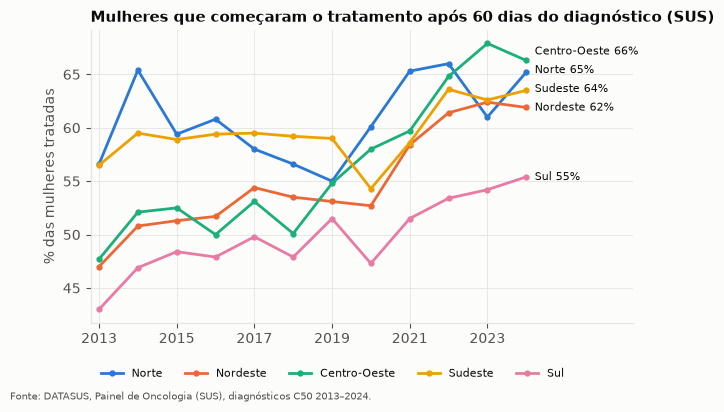

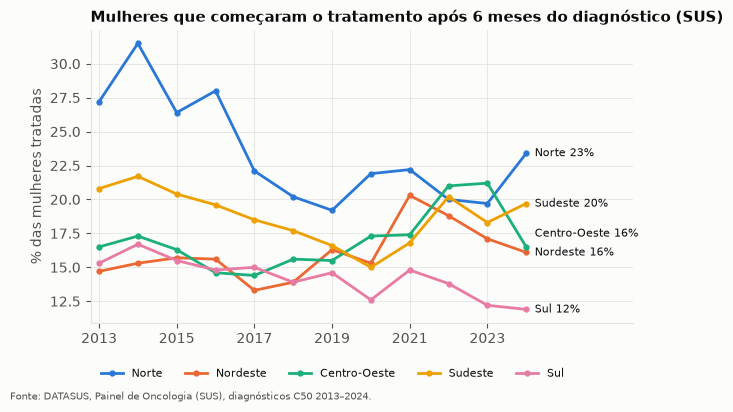

In [8]:
por_ano = tempos.resumo(painel, "dias_diagnostico_tratamento", ["ano_diagnostico", "regiao_res"]).rename(columns={"regiao_res": "regiao"})
base.salvar_tabela(por_ano, "06_painel_tempo_ano_regiao")
fig, ax = g.linhas(por_ano, "ano_diagnostico", "pct_mais_60_dias", "regiao",
                   "Mulheres que começaram o tratamento após 60 dias do diagnóstico (SUS)",
                   "% das mulheres tratadas", fmt="{:.0f}%", ordem=c.REGIOES)
g.salvar(fig, "06_mais_60_dias_tendencia", FONTE_PAINEL)
plt.show()
fig, ax = g.linhas(por_ano, "ano_diagnostico", "pct_mais_6_meses", "regiao",
                   "Mulheres que começaram o tratamento após 6 meses do diagnóstico (SUS)",
                   "% das mulheres tratadas", fmt="{:.0f}%", ordem=c.REGIOES)
g.salvar(fig, "06_mais_6_meses_tendencia", FONTE_PAINEL)
plt.show()

O cumprimento da lei piorou em vez de melhorar. Em 2013, entre 43% (Sul) e 57% (Norte e Sudeste) das mulheres passavam dos 60 dias. A partir de 2020 esses percentuais sobem em todas as regiões, e em 2024 ficam entre 55% e 66%. A segunda figura mostra que a parcela que espera mais de 6 meses também cresceu. A pandemia explica parte do salto de 2020 e 2021, mas a piora continua depois dela, o que sugere que a demanda cresceu mais rápido que a capacidade de tratamento.

## A espera pela radioterapia

A radioterapia merece uma seção própria. Ela costuma vir depois da cirurgia ou da quimioterapia, e depende de aparelhos caros e concentrados em poucos serviços (caderno 09). A APAC de radioterapia registra, para cada mulher, a data do diagnóstico e a data de início da radioterapia. Usamos as mulheres que começaram a radioterapia pelo SUS em 2023 ou 2024.

Aqui o tempo não deve ser comparado com os 60 dias da lei, porque a radioterapia raramente é o primeiro tratamento: ela vem depois de meses de cirurgia e quimioterapia. O interesse está em comparar as regiões e ver o quanto a espera total se estende.

68,626 mulheres iniciaram radioterapia para câncer de mama pelo SUS em 2023 ou 2024


finalidade,Adjuvante,Radical,Paliativa,Antiálgica,Prévia,Anti-hemorrágica,Sem informação
regiao_res,,,,,,,
Norte,62.3,34.6,2.5,0.3,0.1,0.1,0.0
Nordeste,84.9,11.6,1.8,0.1,1.1,0.4,0.0
Centro-Oeste,87.4,9.7,2.0,0.3,0.3,0.2,0.0
Sudeste,79.3,13.0,4.3,0.9,2.3,0.2,0.1
Sul,85.5,9.2,3.0,0.1,1.7,0.5,0.0


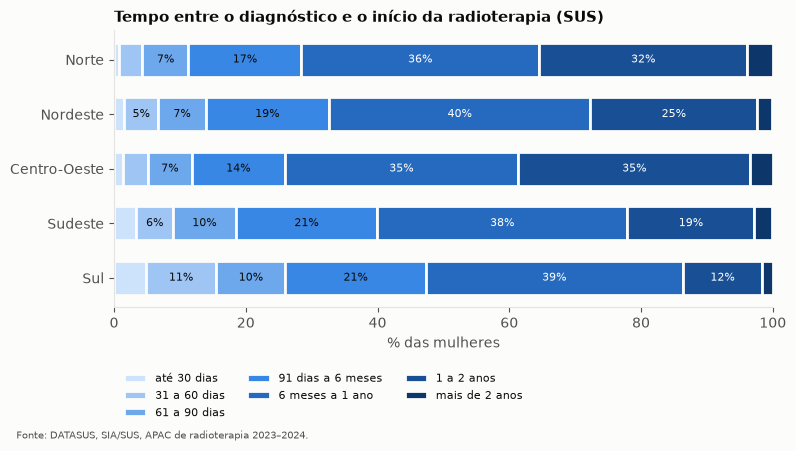

,regiao_res,n,mediana,p25,p75,pct_mais_60_dias,pct_mais_6_meses,pct_mais_1_ano
0,Centro-Oeste,3995,309.0,172.0,438.0,94.9,74.0,38.6
1,Nordeste,15439,276.0,139.0,378.0,93.3,67.3,27.6
2,Norte,3015,294.0,157.0,433.0,95.7,71.6,35.5
3,Sudeste,31116,232.0,112.0,351.0,91.1,60.1,22.1
4,Sul,14750,193.0,88.0,306.0,84.5,52.7,13.7


In [9]:
radio = base.carregar("apac_radio_pacientes")
radio = radio[radio.regiao_res.notna()]
print(f"{len(radio):,} mulheres iniciaram radioterapia para câncer de mama pelo SUS em 2023 ou 2024")
display(base.distribuicao(radio, "finalidade", ordem=["Adjuvante", "Radical", "Paliativa", "Antiálgica", "Prévia",
                                                    "Anti-hemorrágica", c.SEM_INFO]))
dist_radio = tempos.distribuicao_intervalos(radio, "dias_diagnostico_radioterapia", "regiao_res")
res_radio = tempos.resumo(radio, "dias_diagnostico_radioterapia", ["regiao_res"])
base.salvar_tabela(dist_radio, "06_radioterapia_faixas_tempo_regiao", index=True)
base.salvar_tabela(res_radio, "06_radioterapia_resumo_tempo_regiao")
fig, ax = g.empilhadas_100(dist_radio, "Tempo entre o diagnóstico e o início da radioterapia (SUS)",
                           "% das mulheres", cores=CORES_TEMPO, minimo_rotulo=5, figsize=(8.5, 3.6))
g.salvar(fig, "06_radioterapia_faixas_tempo", "DATASUS, SIA/SUS, APAC de radioterapia 2023–2024.")
plt.show()
res_radio

Quatro em cada cinco radioterapias (82%) são adjuvantes, ou seja, feitas depois da cirurgia para eliminar células que possam ter restado. Por isso é esperado que elas comecem meses depois do diagnóstico. Mesmo assim, as diferenças entre regiões são grandes. No Sul, a mediana entre o diagnóstico e o início da radioterapia é de 193 dias, pouco mais de 6 meses. No Sudeste é de 232 dias, no Nordeste 276, no Norte 294 e no Centro-Oeste 309 dias, mais de 10 meses.

A parcela que espera mais de um ano mostra a mesma ordem: 14% no Sul, 22% no Sudeste, 28% no Nordeste, 36% no Norte e 39% no Centro-Oeste. Diretrizes clínicas recomendam, em geral, que a radioterapia adjuvante comece poucas semanas depois da cirurgia ou da quimioterapia, e esperas de um ano estão muito além disso. É coerente com o caderno 09: o Sul tem a maior oferta de serviços de radioterapia por mulher (2,4 por milhão), mais que o dobro de Norte, Nordeste e Centro-Oeste (entre 0,9 e 1,1 por milhão).

## Cuidados ao citar estes números

O Painel registra apenas o primeiro tratamento feito no SUS. Mulheres que começaram o tratamento na rede privada e depois migraram para o SUS podem aparecer com tempos longos. Entre 11% e 18% dos casos não têm tratamento registrado, e não entram no cálculo. Tratamentos registrados antes da data do diagnóstico foram considerados como tempo zero. No RHC, intervalos negativos ou maiores que 10 anos foram descartados como erro de digitação.

## O que levar para o TCC

Em todas as regiões, metade ou mais das mulheres tratadas no SUS começa o tratamento depois do prazo de 60 dias, e uma em cada seis espera mais de 6 meses. A situação piorou desde 2020. O Norte tem as esperas mais longas, e mulheres pretas e com menor escolaridade esperam mais. Esse atraso se soma ao diagnóstico tardio do caderno 04 e reforça o argumento do projeto por ferramentas que acelerem a detecção e o acompanhamento.